# HW4-3 CIFAR-10 CNN

使用 CIFAR-10 資料集建立 CNN，進行 10 種圖片分類。

## 1. 匯入套件

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from ipywidgets import interact_manual, IntSlider

np.random.seed(42)
tf.random.set_seed(42)

## 2. 讀取 CIFAR-10 資料

圖片大小是 32 × 32，包含 RGB 三個色彩通道。

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("訓練圖片：", x_train.shape)
print("訓練標籤：", y_train.shape)
print("測試圖片：", x_test.shape)
print("測試標籤：", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2030s 12us/step
訓練圖片： (50000, 32, 32, 3)
訓練標籤： (50000, 1)
測試圖片： (10000, 32, 32, 3)
測試標籤： (10000, 1)


## 3. 訓練圖片

顯示訓練圖片與正確的類別名稱。

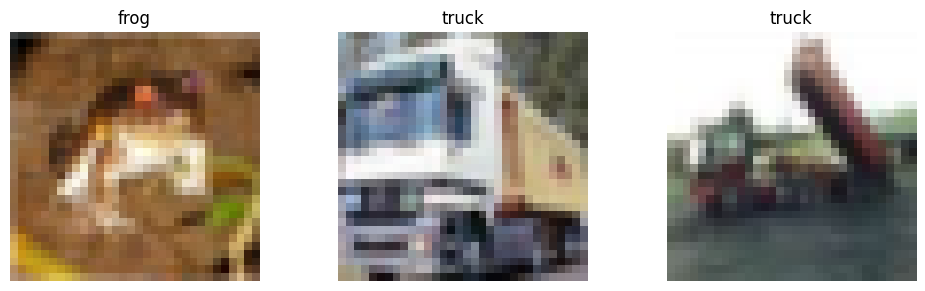

In [3]:
plt.figure(figsize=(10, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i, 0])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. 資料預處理

圖片除以 255 進行正規化，標籤使用 one-hot encoding。

In [4]:
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

y_train_onehot = to_categorical(y_train.reshape(-1), 10)
y_test_onehot = to_categorical(y_test.reshape(-1), 10)

print("x_train_norm：", x_train_norm.shape)
print("x_test_norm：", x_test_norm.shape)
print("y_train_onehot：", y_train_onehot.shape)
print("y_test_onehot：", y_test_onehot.shape)

x_train_norm： (50000, 32, 32, 3)
x_test_norm： (10000, 32, 32, 3)
y_train_onehot： (50000, 10)
y_test_onehot： (10000, 10)


## 5. 建立 CNN 模型

包含三組卷積與池化層，最後以兩層全連接層進行分類。

In [5]:
model = Sequential([
    Input(shape=(32, 32, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    Dropout(0.3),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), padding="same", activation="relu"),
    Dropout(0.3),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), padding="same", activation="relu"),
    Dropout(0.3),
    Conv2D(128, (3, 3), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dropout(0.3),
    Dense(2500, activation="relu"),
    Dropout(0.3),
    Dense(1500, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2500)           │     5,122,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1500)           │     3,751,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        15,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,176,018 (35.00 MB)

 Trainable params: 9,176,018 (35.00 MB)

 Non-trainable params: 0 (0.00 B)

## 6. 各層 shape 與參數量

批次大小為 128，輸入 shape 為 `(128, 32, 32, 3)`，卷積使用 `padding="same"`。

卷積層參數 = `(3 × 3 × 輸入通道 + 1) × Filter 數`。

全連接層參數 = `(輸入神經元 + 1) × 輸出神經元`。

Dropout、池化層與 Flatten 都沒有訓練參數。

In [6]:
batch_size = 128
print("批次 input shape：", (batch_size, 32, 32, 3))

for layer in model.layers:
    shape = tuple(batch_size if d is None else int(d) for d in layer.output.shape)
    print(layer.name, "output shape:", shape, "params:", layer.count_params())

print("模型總參數：", model.count_params())

批次 input shape： (128, 32, 32, 3)
conv2d output shape: (128, 32, 32, 32) params: 896
dropout output shape: (128, 32, 32, 32) params: 0
conv2d_1 output shape: (128, 32, 32, 32) params: 9248
max_pooling2d output shape: (128, 16, 16, 32) params: 0
conv2d_2 output shape: (128, 16, 16, 64) params: 18496
dropout_1 output shape: (128, 16, 16, 64) params: 0
conv2d_3 output shape: (128, 16, 16, 64) params: 36928
max_pooling2d_1 output shape: (128, 8, 8, 64) params: 0
conv2d_4 output shape: (128, 8, 8, 128) params: 73856
dropout_2 output shape: (128, 8, 8, 128) params: 0
conv2d_5 output shape: (128, 8, 8, 128) params: 147584
max_pooling2d_2 output shape: (128, 4, 4, 128) params: 0
flatten output shape: (128, 2048) params: 0
dropout_3 output shape: (128, 2048) params: 0
dense output shape: (128, 2500) params: 5122500
dropout_4 output shape: (128, 2500) params: 0
dense_1 output shape: (128, 1500) params: 3751500
dropout_5 output shape: (128, 1500) params: 0
dense_2 output shape: (128, 10) params: 1

### 參數數量計算

In [7]:
params = [
    ("Conv2D 32 (第1層)", (3*3*3+1)*32),
    ("Conv2D 32 (第3層)", (3*3*32+1)*32),
    ("Conv2D 64 (第5層)", (3*3*32+1)*64),
    ("Conv2D 64 (第7層)", (3*3*64+1)*64),
    ("Conv2D 128 (第9層)", (3*3*64+1)*128),
    ("Conv2D 128 (第11層)", (3*3*128+1)*128),
    ("Dense 2500 (第15層)", (4*4*128+1)*2500),
    ("Dense 1500 (第17層)", (2500+1)*1500),
    ("Dense 10 (第19層)", (1500+1)*10)
]

for name, count in params:
    print(name, ":", count)
print("計算總數：", sum(count for _, count in params))
print("模型總數：", model.count_params())
assert sum(count for _, count in params) == model.count_params()

Conv2D 32 (第1層) : 896
Conv2D 32 (第3層) : 9248
Conv2D 64 (第5層) : 18496
Conv2D 64 (第7層) : 36928
Conv2D 128 (第9層) : 73856
Conv2D 128 (第11層) : 147584
Dense 2500 (第15層) : 5122500
Dense 1500 (第17層) : 3751500
Dense 10 (第19層) : 15010
計算總數： 9176018
模型總數： 9176018


## 7. 編譯與訓練

使用 `categorical_crossentropy`、`adam`，訓練 50 個 epochs，
每批 128 筆，取 20% 訓練資料作為驗證資料。

In [8]:
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

history = model.fit(
    x_train_norm,
    y_train_onehot,
    validation_split=0.2,
    epochs=50,
    batch_size=128,
    verbose=1
)

Epoch 1/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 343s 1s/step - accuracy: 0.3251 - loss: 1.8003 - val_accuracy: 0.4478 - val_loss: 1.5118
Epoch 2/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 340s 1s/step - accuracy: 0.5077 - loss: 1.3470 - val_accuracy: 0.5834 - val_loss: 1.1714
Epoch 3/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 377s 1s/step - accuracy: 0.5840 - loss: 1.1537 - val_accuracy: 0.6307 - val_loss: 1.0370
Epoch 4/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 381s 1s/step - accuracy: 0.6320 - loss: 1.0324 - val_accuracy: 0.6675 - val_loss: 0.9378
Epoch 5/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 383s 1s/step - accuracy: 0.6672 - loss: 0.9339 - val_accuracy: 0.6874 - val_loss: 0.8805
Epoch 6/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 382s 1s/step - accuracy: 0.6975 - loss: 0.8562 - val_accuracy: 0.7164 - val_loss: 0.7945
Epoch 7/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 341s 1s/step - accuracy: 0.7169 - loss: 0.8004 - val_accuracy: 0.7339 - val_loss: 0.7521
Epoch 8/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 380s 1s/step - accuracy: 0.7336 - loss: 0.7455 - val_accu

## 8. Accuracy 與 Loss

比較訓練資料和驗證資料的變化，觀察是否有 overfitting。

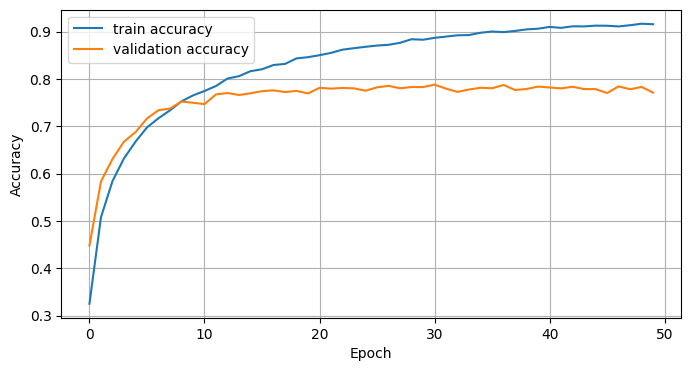

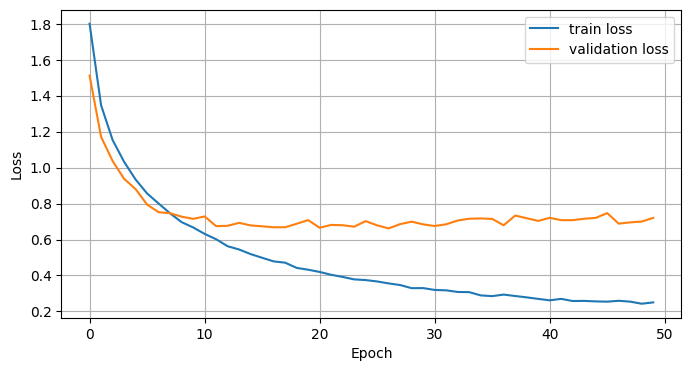

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

### Overfitting 觀察

In [10]:
best_epoch = int(np.argmax(history.history["val_accuracy"])) + 1
print("最高 validation accuracy：", round(max(history.history["val_accuracy"]), 4))
print("出現在第", best_epoch, "個 epoch")
print("最後 train accuracy：", round(history.history["accuracy"][-1], 4))
print("最後 validation accuracy：", round(history.history["val_accuracy"][-1], 4))

if history.history["loss"][-1] < history.history["loss"][best_epoch - 1] and history.history["val_loss"][-1] > history.history["val_loss"][best_epoch - 1]:
    print("後期 train loss 下降、validation loss 上升，可能有 overfitting。")
else:
    print("可對照上面的 loss 與 accuracy 曲線觀察 overfitting。")

最高 validation accuracy： 0.7879
出現在第 31 個 epoch
最後 train accuracy： 0.9155
最後 validation accuracy： 0.771
後期 train loss 下降、validation loss 上升，可能有 overfitting。


## 9. 測試資料評估

以全部 10000 筆測試資料評估。

In [11]:
test_loss, test_accuracy = model.evaluate(x_test_norm, y_test_onehot, verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print("Test accuracy (%):", test_accuracy * 100)

Test loss: 0.7424631118774414
Test accuracy: 0.7710000276565552
Test accuracy (%): 77.10000276565552


## 10. 測試資料預測

對全部測試資料預測，並顯示預測與正確的類別名稱。

79/79 ━━━━━━━━━━━━━━━━━━━━ 18s 225ms/step
測試 input shape: (10000, 32, 32, 3)
預測 output shape: (10000, 10)


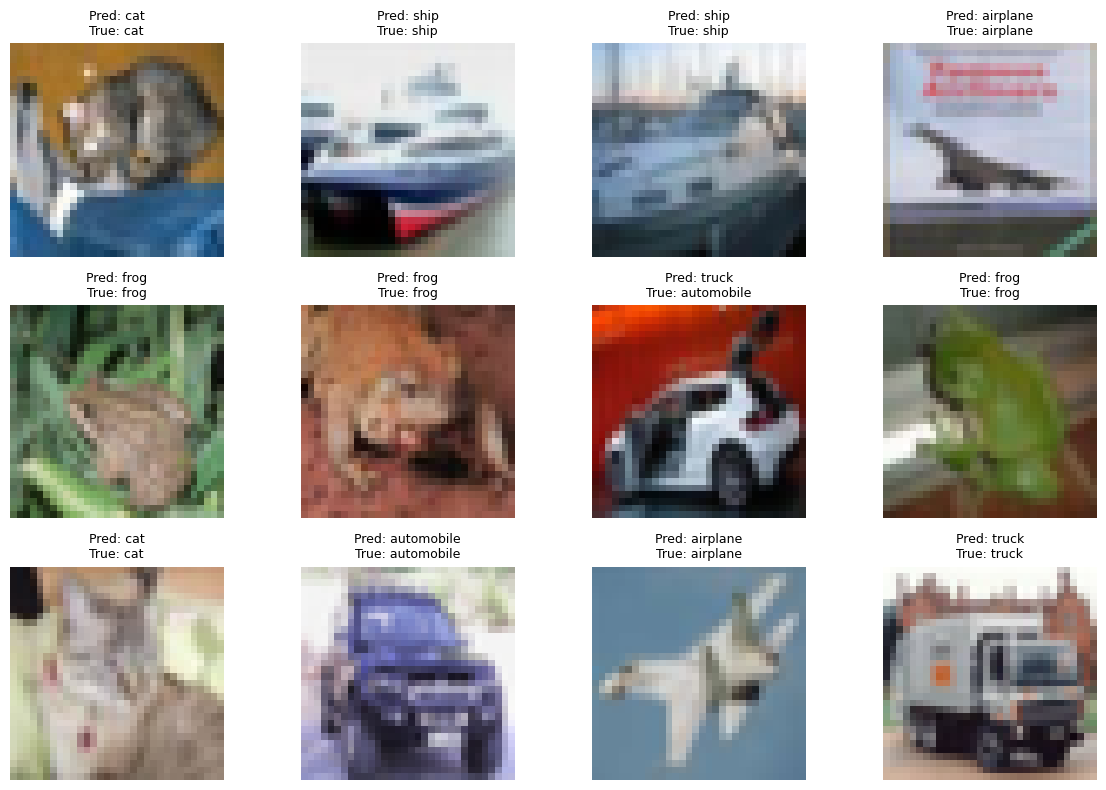

In [12]:
prediction = model.predict(x_test_norm, batch_size=128)
predicted_labels = np.argmax(prediction, axis=1)
true_labels = y_test.reshape(-1)

print("測試 input shape:", x_test_norm.shape)
print("預測 output shape:", prediction.shape)

plt.figure(figsize=(12, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i])
    plt.title(
        "Pred: " + class_names[predicted_labels[i]] + "\nTrue: " + class_names[true_labels[i]],
        fontsize=9
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

## 11. Confusion Matrix

[[768  18  54  19  19  14  13  11  61  23]
 [  8 916   2   8   6   2   6   0  12  40]
 [ 41   2 684  63  73  33  72  17  11   4]
 [ 14   5  60 646  73  97  70  24   6   5]
 [  5   3  52  50 793  12  44  34   5   2]
 [  7   1  58 237  51 570  37  33   4   2]
 [  3   3  25  58  36  10 858   3   3   1]
 [ 10   3  30  52  72  28  14 782   4   5]
 [ 44  25  15  11  13   6  10   2 860  14]
 [ 20  74   6  23   5   9   9   7  14 833]]


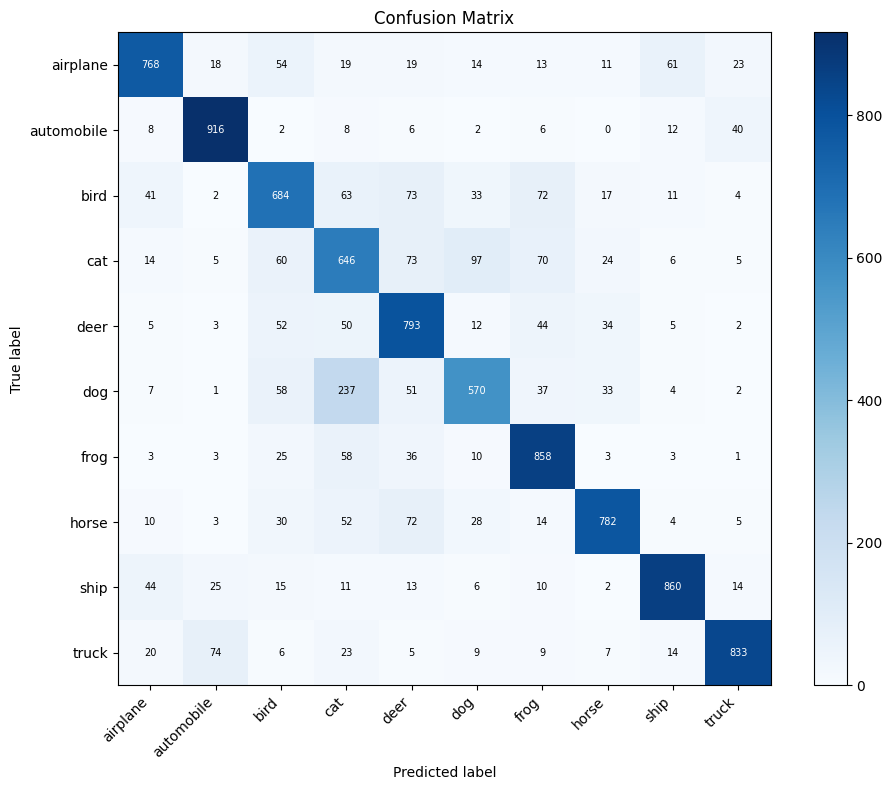

In [13]:
cm = tf.math.confusion_matrix(true_labels, predicted_labels, num_classes=10).numpy()
print(cm)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

## 12. 儲存完整模型

將模型儲存成 `.keras` 檔。

In [14]:
model.save("cifar10_cnn_hw4_3.keras")
print("模型已儲存：cifar10_cnn_hw4_3.keras")

模型已儲存：cifar10_cnn_hw4_3.keras


## 13. interact_manual 預測

輸入測試圖片的編號，按下按鈕查看預測結果。

In [15]:
def show_prediction(index):
    plt.figure(figsize=(4, 4))
    plt.imshow(x_test[index])
    plt.axis("off")
    plt.title("Pred: " + class_names[predicted_labels[index]] +
              "\nTrue: " + class_names[true_labels[index]])
    plt.show()
    print("預測信心度：", round(float(np.max(prediction[index])) * 100, 2), "%")

interact_manual(show_prediction, index=IntSlider(value=0, min=0, max=9999, step=1, description="圖片編號"))

interactive(children=(IntSlider(value=0, description='圖片編號', max=9999), Button(description='Run Interact', sty…

<function __main__.show_prediction(index)>

## 14. 比較模型結果

比較 HW4-2 與 HW4-3 的測試準確率、loss、參數量與訓練結果。

In [16]:
hw42_test_accuracy = 0.7023000121116638
hw42_test_loss = 0.9741506576538086
hw42_total_params = 4226506
hw42_train_accuracy = 0.9287
hw42_val_accuracy = 0.7077

print("HW4-2 測試準確率：", round(hw42_test_accuracy * 100, 2), "%")
print("HW4-3 測試準確率：", round(test_accuracy * 100, 2), "%")
print("準確率差距：", round((test_accuracy - hw42_test_accuracy) * 100, 2), "個百分點")
print("HW4-2 Test loss：", round(hw42_test_loss, 4))
print("HW4-3 Test loss：", round(test_loss, 4))
print("HW4-2 參數量：", hw42_total_params)
print("HW4-3 參數量：", model.count_params())
print("HW4-2 最後 train accuracy：", hw42_train_accuracy)
print("HW4-3 最後 train accuracy：", round(history.history["accuracy"][-1], 4))
print("HW4-2 最後 validation accuracy：", hw42_val_accuracy)
print("HW4-3 最後 validation accuracy：", round(history.history["val_accuracy"][-1], 4))

HW4-2 測試準確率： 70.23 %
HW4-3 測試準確率： 77.1 %
準確率差距： 6.87 個百分點
HW4-2 Test loss： 0.9742
HW4-3 Test loss： 0.7425
HW4-2 參數量： 4226506
HW4-3 參數量： 9176018
HW4-2 最後 train accuracy： 0.9287
HW4-3 最後 train accuracy： 0.9155
HW4-2 最後 validation accuracy： 0.7077
HW4-3 最後 validation accuracy： 0.771


## 15. 結果

比較 HW4-2 與 HW4-3 的測試準確率、loss、參數量，
並從訓練及驗證曲線觀察是否有 overfitting。